# 05 · Battery value
1 MW / 2 MWh, 90 % round-trip efficiency, max one cycle per day, no degradation (all configurable in `src/battery.py`). Each day a small LP picks charge/discharge hours on the *schedule* prices; revenue is settled at *actual* prices.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
R = ROOT / "reports"
plt.rcParams.update({"figure.figsize": (11, 4.2), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
ACC, BLUE, TEAL, RED, GREY = "#E08E0B", "#3F6FD8", "#1E9E92", "#D64545", "#7A8194"
pd.set_option("display.float_format", "{:,.2f}".format)


,total_eur,eur_per_mw_year,pct_of_perfect,days
strategy,,,,
perfect_foresight,"265,807.20","113,739.30",100.00,853
forecast_lightgbm,"234,558.30","100,367.90",88.20,853
forecast_ensemble,"236,788.50","101,322.20",89.10,853
naive_yesterday,"221,856.80","94,932.90",83.50,853


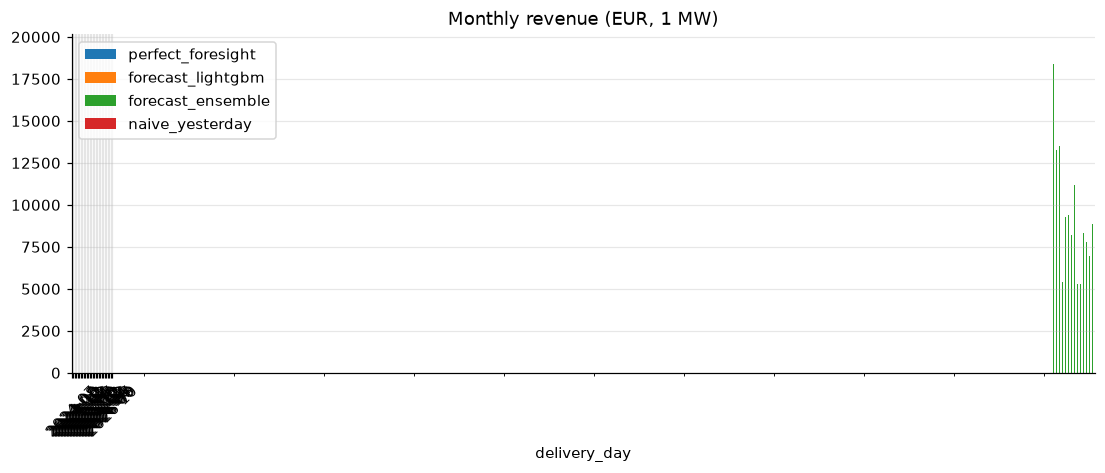

Takeaway: perfect foresight €113,739/MW-yr; LightGBM schedule captures 88% (€100,368), naive 83% (€94,933). Value of the forecast over naive: €5,435/MW-yr.


In [2]:
br = pd.read_csv(R / "battery_results.csv", index_col=0); display(br.round(1))
bd = pd.read_csv(R / "battery_daily.csv", parse_dates=["delivery_day"]).set_index("delivery_day")
bd.resample("MS").sum().plot.bar(figsize=(12, 4), title="Monthly revenue (EUR, 1 MW)")
plt.xticks(range(len(bd.resample("MS").sum())), [d.strftime("%Y-%m") for d in bd.resample("MS").sum().index], rotation=45); plt.show()
pf, fc, nv = br.loc["perfect_foresight"], br.loc["forecast_lightgbm"], br.loc["naive_yesterday"]
print(f"Takeaway: perfect foresight €{pf.eur_per_mw_year:,.0f}/MW-yr; LightGBM schedule captures {fc.pct_of_perfect:.0f}% "
      f"(€{fc.eur_per_mw_year:,.0f}), naive {nv.pct_of_perfect:.0f}% (€{nv.eur_per_mw_year:,.0f}). "
      f"Value of the forecast over naive: €{fc.eur_per_mw_year - nv.eur_per_mw_year:,.0f}/MW-yr.")

## Sensitivity: duration and efficiency

In [3]:
se = pd.read_csv(R / "battery_sensitivity.csv")
display(se.pivot_table(index=["duration_h", "efficiency"], columns="strategy", values="eur_per_mw_year").round(0))
display(se[se.efficiency == .9].pivot_table(index="duration_h", columns="strategy", values="pct_of_perfect").round(1))

strategy               forecast_lightgbm  naive_yesterday  perfect_foresight
duration_h efficiency                                                       
1          0.80                47,349.00        44,455.00          55,672.00
           0.85                50,262.00        47,359.00          58,642.00
           0.90                53,050.00        50,134.00          61,492.00
           0.95                55,744.00        52,796.00          64,233.00
2          0.80                89,612.00        84,091.00         102,834.00
           0.85                95,111.00        89,642.00         108,405.00
           0.90               100,368.00        94,933.00         113,739.00
           0.95               105,444.00       100,004.00         118,860.00
4          0.80               159,260.00       149,280.00         174,652.00
           0.85               169,467.00       159,637.00         184,776.00
           0.90               179,213.00       169,404.00         194,446.00
           0.95               188,481.00       178,753.00         203,697.00

strategy,forecast_lightgbm,naive_yesterday,perfect_foresight
duration_h,,,
1,86.30,81.50,100.00
2,88.20,83.50,100.00
4,92.20,87.10,100.00


## Effect of price level / spread

In [4]:
h = pd.read_parquet(ROOT / "data/processed/hourly.parquet"); h.index = h.index.tz_convert("Europe/Sofia")
d = h.price_BG.groupby(h.index.date).agg(["mean", lambda s: s.max() - s.min()]); d.columns = ["level", "spread"]
d.index = pd.to_datetime(d.index); j = bd.join(d, how="inner")
for c in ["level", "spread"]:
    q = pd.qcut(j[c], 4, labels=["Q1", "Q2", "Q3", "Q4"])
    print(f"Avg daily perfect-foresight revenue by {c} quartile:", j.groupby(q, observed=True).perfect_foresight.mean().round(0).to_dict())

Avg daily perfect-foresight revenue by level quartile: {'Q1': 295.0, 'Q2': 275.0, 'Q3': 253.0, 'Q4': 423.0}
Avg daily perfect-foresight revenue by spread quartile: {'Q1': 134.0, 'Q2': 249.0, 'Q3': 322.0, 'Q4': 542.0}


## Costs, confidence filter and reserve capacity

strategy,forecast_lightgbm,naive_yesterday,perfect_foresight
degradation_eur_mwh,,,
0,"100,368.00","94,933.00","113,739.00"
3,"98,175.00","92,740.00","111,546.00"
6,"95,982.00","90,547.00","109,353.00"
10,"93,058.00","87,623.00","106,429.00"
15,"89,403.00","83,968.00","102,774.00"


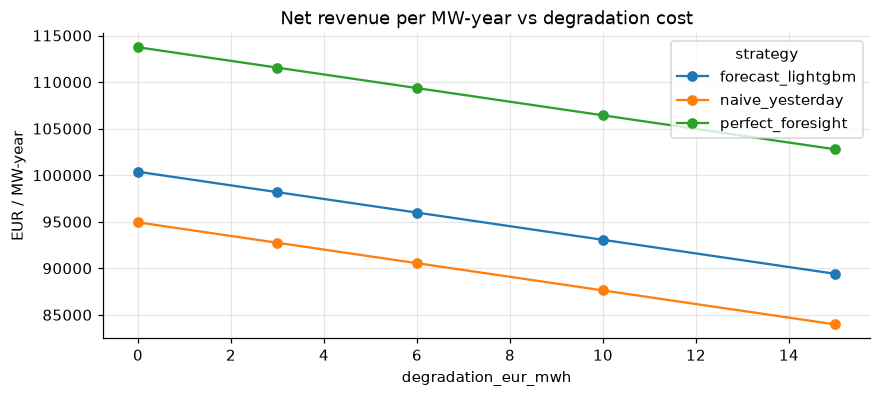

split,cv,holdout
min_expected_profit,,
0,"102,225.00","85,008.00"
5,"102,225.00","85,008.00"
10,"102,225.00","85,008.00"
20,"102,225.00","85,008.00"
40,"102,225.00","85,008.00"
80,"101,894.00","84,999.00"
120,"100,403.00","84,305.00"


Confidence-filter threshold chosen on CV: {'min_expected_profit_eur_per_mw_day': 0.0, 'rule': 'chosen on CV months only'}


In [5]:
dg = pd.read_csv(R / "battery_degradation.csv")
display(dg.pivot(index="degradation_eur_mwh", columns="strategy", values="eur_per_mw_year").round(0))
dg.pivot(index="degradation_eur_mwh", columns="strategy", values="eur_per_mw_year").plot(marker="o", figsize=(9, 3.6), title="Net revenue per MW-year vs degradation cost")
plt.ylabel("EUR / MW-year"); plt.show()
fl = pd.read_csv(R / "battery_filter.csv"); display(fl.pivot(index="min_expected_profit", columns="split", values="eur_per_mw_year").round(0))
print("Confidence-filter threshold chosen on CV:", json.loads((R / "battery_filter_choice.json").read_text()))

Each EUR 5/MWh of wear cost removes roughly EUR 3.6k per MW-year. The confidence filter adds nothing: Bulgarian daily spreads always cover the round-trip losses, so the best threshold on the CV months is zero.

,product,price_eur_mw_h,contracted_mw,capacity_eur_per_mw_year_100pct,arbitrage_eur_per_mw_year,fleet_mw_that_would_be_10pct_of_market
0,FCR (symmetric),27.30,28.70,"239,352.40","100,367.90",2.90
1,aFRR up,27.30,109.50,"239,381.60","100,367.90",11.00
2,aFRR down,5.40,100.00,"47,442.70","100,367.90",10.00
3,mFRR up,5.40,565.70,"47,442.70","100,367.90",56.60


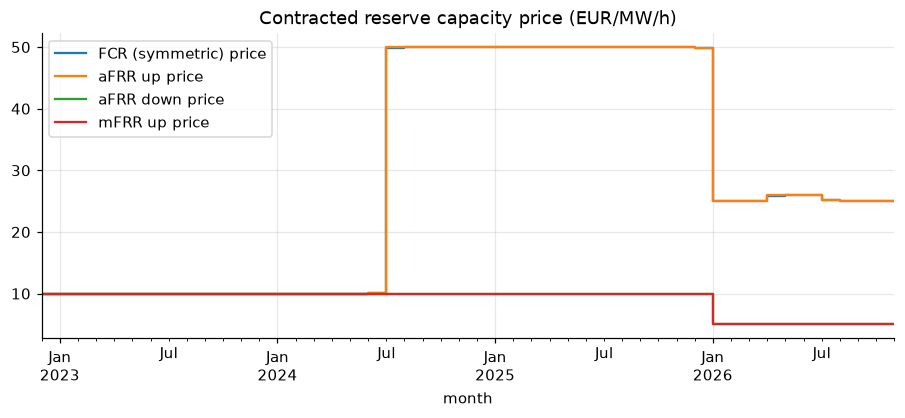

In [6]:
rv = pd.read_csv(R / "battery_reserve.csv"); display(rv.round(1))
rm = pd.read_csv(R / "reserve_monthly.csv", parse_dates=["month"]).set_index("month")
rm[[c for c in rm if c.endswith(" price")]].plot(drawstyle="steps-post", figsize=(10, 3.6), title="Contracted reserve capacity price (EUR/MW/h)"); plt.show()

**Read with care.** The reserve prices are constant for long stretches (administered, not competitively cleared) and the markets are tiny (FCR ~29 MW, aFRR-up ~110 MW contracted), so one battery is a large share and a fleet saturates them; the price-taker assumption fails. Only the capacity payment is counted. Break-even capex and payback are available as sliders on the dashboard.

**Limitations:** day-ahead arbitrage only (no intraday, aFRR/mFRR or capacity revenue, which dominate real battery business cases), price-taker, no network charges or degradation, one cycle per day. The numbers are a floor for the arbitrage component, not a full investment case.